# Worked Example, Milestone 1: Proposal + EDA
## Did free fares raise weekday ridership on Boston's bus routes 23, 28 and 29?

**What this is.** Part 2 of the Final Project starter notebook, filled in for one topic, as it would be handed in
with the two-page proposal at Milestone 1. The example proposal (Word) quotes every number from this notebook's
last cell.

**What it is not.** A topic you can use. Neither course's worked example, its data or its question, may be used for
a project. Copy the structure: the decision first, the design named with who is treated, the data's quirks written
down, means by group, the figure the design rests on, one finding and one concern.

## Part 2: The Decision, the Design, and the Data

### Research design

- **Client and decision:** the City of Boston, which pays the MBTA to keep routes 23, 28 and 29 fare-free, and must
  decide whether to pay for 2027. The current extension runs through December 2026.
- **Decides it:** written before any estimate. The city has paid about $350k a month. Charging all of it to
  new weekday trips (an upper bound on the cost per trip, because weekend trips are free too), each added weekday
  boarding costs less than the $1.70 fare it replaces if free fares added at least **9,466** weekday
  boardings across the three routes: **37.1%** of their Fall 2019 total of 25,516. Most of the
  payment is a transfer to people who already ride, which the city may value for its own sake; the report will show
  both readings.
- **Causal question:** did making the three routes free raise their average weekday boardings, and by how much?
- **Why prediction is not enough:** a model of ridership would predict the three routes' recovery well from their
  own history and from every other route's. It cannot say how much of that recovery the free fare caused, which is
  the only part the city is paying for.
- **Design and estimand:** difference-in-differences with a staggered start (Topic 11). The estimand is the average
  effect on the treated routes, in log points of weekday boardings, over the falls after each went free.
- **The comparison:** the 133 other routes that ran in all ten falls, Fall 2016 to Fall 2025.
- **Who is treated:** 3 routes. Route 28 from Fall 2021 (free from 29 August 2021); routes 23 and 29 from
  Fall 2022 (free from 1 March 2022).
- **Key assumption:** parallel trends. Without free fares, the three routes' log ridership would have moved like the
  comparison routes' from Fall 2019 on, including through the pandemic.
- **How we will check it:** pre-period event-study coefficients (Fall 2016 to 2019); routes 23 and 29 in Fall 2021,
  when they still charged, as a placebo; and permutation inference, giving each comparison route the treated
  routes' dates in turn, because three treated routes are too few for clustered standard errors.
- **The threat we fear most:** these routes serve riders who kept riding through the pandemic. If they held up
  better for that reason, the estimate is **too large**. The data below show the gap opening in Fall 2020, before any
  route was free.

### The data

MBTA Blue Book Open Data Portal, "MBTA Bus Ridership by Trip, Season, Route, Line, and Stop" (ArcGIS item
`8daf4a33925a4df59183f860826d29ee`): one row per stop on each scheduled trip, with the average boardings there across
the sampled days. The 73 MB zip unpacks to 1.0 GB, so `build_mbta_table.py` (published beside this notebook) reduces it to one row per
route and fall, weekday boardings summed over trips and stops, and this notebook loads that small table.

Three things in the raw files that a one-line loader gets wrong, all handled in `build_mbta_table.py`:

1. **Three layouts.** Fall 2016 to 2023 have `season = "Fall 2016"`; Fall 2024 has `season = "Fall"` and a separate
   `year`; Fall 2025 renames every column (`"GTFS route_id"`, `"Day Type"`, `"Boardings"`). The fall is taken from
   the file name.
2. **Fall 2025 splits Friday from the other weekdays** (`Wkdy` and `Fri`). `Wkdy` is used; for route 28 the two are
   10,894 and 10,892 boardings, so the choice does not move the series.
3. **Route ids are text.** "34E", "57A" and "70A" are routes; read as numbers they fail or merge.

In [1]:
import json
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

DATA_URL = ("https://raw.githubusercontent.com/RyanPiao/econ5200-student-notebooks/main/5200/"
            "mbta_route_fall_weekday.csv")
LOCAL = "mbta_route_fall_weekday.csv"
rides = pd.read_csv(LOCAL if os.path.exists(LOCAL) else DATA_URL, dtype={"route": str})

TREATED = {"28": 2021, "23": 2022, "29": 2022}     # route: first fall it was free
print(rides.shape)
rides.head()

(1564, 3)


,route,fall,boardings
0,1,2016,11416.3
1,1,2017,11925.0
2,1,2018,11831.4
3,1,2019,14257.0
4,1,2020,5562.7


**The sample rule.** Keep the routes that ran in every fall from 2016 to 2025, so every route is compared with itself
over the whole period. Routes that started, ended or were renumbered drop out; the cell prints how many.

In [2]:
falls = sorted(rides["fall"].unique())
n_falls = rides.groupby("route")["fall"].nunique()
keep = n_falls[n_falls == len(falls)].index
panel = rides[rides["route"].isin(keep)].copy()
panel["treated_route"] = panel["route"].isin(list(TREATED)).astype(int)
panel["log_boardings"] = np.log(panel["boardings"])

print(f"{rides['route'].nunique()} route ids in the files; {len(keep)} ran in all {len(falls)} falls "
      f"({falls[0]} to {falls[-1]}): {len(panel):,} route-falls")
print(f"treated: {sorted(TREATED)}; comparison routes: {len(keep) - len(TREATED)}")
assert set(TREATED) <= set(keep), "a treated route is missing a fall"

177 route ids in the files; 136 ran in all 10 falls (2016 to 2025): 1,360 route-falls
treated: ['23', '28', '29']; comparison routes: 133


### Table 1: the treated routes against the comparison routes, before any route was free

In [3]:
def balance_table(data, group, cols):
    """Means by group, the difference, and the standardised difference (difference / pooled SD)."""
    g1, g0 = data[data[group] == 1], data[data[group] == 0]
    rows = []
    for c in cols:
        sd = np.sqrt((g1[c].var() + g0[c].var()) / 2)
        rows.append({"variable": c, "treated": g1[c].mean(), "comparison": g0[c].mean(),
                     "difference": g1[c].mean() - g0[c].mean(),
                     "std. difference": (g1[c].mean() - g0[c].mean()) / sd if sd > 0 else np.nan})
    out = pd.DataFrame(rows).set_index("variable")
    out.loc["N (routes)"] = [len(g1), len(g0), np.nan, np.nan]
    return out.round(3)


wide = panel.pivot(index="route", columns="fall", values="log_boardings")
routes = pd.DataFrame({
    "treated_route": wide.index.isin(list(TREATED)).astype(int),
    "weekday boardings, Fall 2019": np.exp(wide[2019]),
    "log change, Fall 2016 to 2019": wide[2019] - wide[2016],
    "log change, Fall 2019 to 2020": wide[2020] - wide[2019],
}, index=wide.index)
table1 = balance_table(routes, "treated_route", routes.columns[1:])
table1

,treated,comparison,difference,std. difference
variable,,,,
"weekday boardings, Fall 2019",8505.267,2664.556,5840.710,1.338
"log change, Fall 2016 to 2019",-0.020,-0.006,-0.014,-0.149
"log change, Fall 2019 to 2020",-0.756,-1.041,0.284,0.883
N (routes),3.000,133.000,NaN,NaN


Before the pandemic both groups were nearly flat: log changes of −0.020 and −0.006 from Fall 2016 to 2019.
Then, in Fall 2020, a year before route 28 went free, the treated routes fell by −0.76 log points against
−1.04 for the comparison routes. That difference opened before the treatment, and it is the threat the design
has to answer. The treated routes are also about three times as busy as the average comparison route
(8,505 weekday boardings against 2,665), so pass 2 also compares them with the busiest
comparison routes alone.

### Figure 1: each treated route against the rest, Fall 2019 = 100

fall   2016  2017  2018  2019  2020  2021  2022  2023  2024  2025
route                                                            
28      107   110   104   100    54    91    94   105   101    93
23      100   101   100   100    48    67    87    97    98   101
29      100   106    96   100    40    52    76    64    57    59
rest [98, 101, 98, 100, 41, 63, 70, 76, 78, 82]


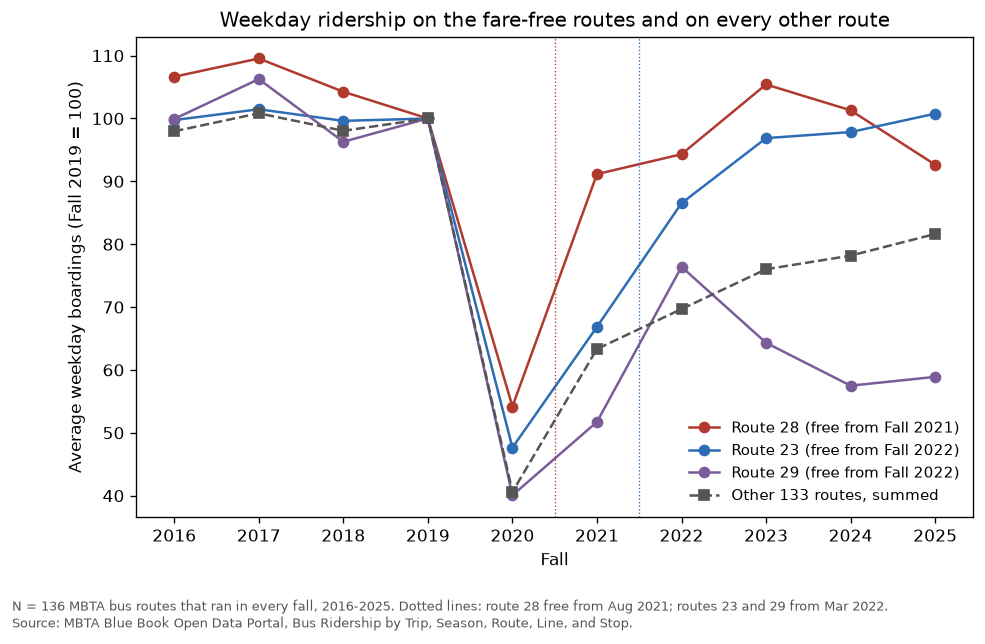

In [4]:
counts = panel.pivot(index="route", columns="fall", values="boardings")
index = counts.div(counts[2019], axis=0) * 100
rest = counts.drop(list(TREATED)).sum()
rest_index = rest / rest[2019] * 100

fig, ax = plt.subplots(figsize=(9, 5.2))
colours = {"28": "#b03a2e", "23": "#2E6DB4", "29": "#7a5c99"}
for r in ["28", "23", "29"]:
    ax.plot(falls, index.loc[r], marker="o", color=colours[r], label=f"Route {r} (free from Fall {TREATED[r]})")
ax.plot(falls, rest_index, marker="s", color="#555555", linestyle="--",
        label=f"Other {len(counts) - len(TREATED)} routes, summed")
ax.axvline(2020.5, color="#b03a2e", linewidth=0.8, linestyle=":")
ax.axvline(2021.5, color="#2E6DB4", linewidth=0.8, linestyle=":")
ax.set_xticks(falls)
ax.set_xlabel("Fall")
ax.set_ylabel("Average weekday boardings (Fall 2019 = 100)")
ax.set_title("Weekday ridership on the fare-free routes and on every other route")
ax.legend(frameon=False, fontsize=9, loc="lower right")
fig.text(0.01, -0.02, f"N = {len(counts)} MBTA bus routes that ran in every fall, 2016-2025. Dotted lines: route 28 "
         "free from Aug 2021; routes 23 and 29 from Mar 2022.\nSource: MBTA Blue Book Open Data Portal, Bus Ridership "
         "by Trip, Season, Route, Line, and Stop.", fontsize=8, color="#555555", va="top")
fig.savefig("figure1_index.png", dpi=300, bbox_inches="tight")
print(index.loc[["28", "23", "29"]].round(0).astype(int).to_string())
print("rest", rest_index.round(0).astype(int).tolist())

**Key finding.** By Fall 2025 routes 28 and 23 stood at 93 and 101 (Fall 2019 = 100), against
82 for the other 133 routes combined. Route 29 stood at 59: it lost riders after 2022
while still free.

**A concern the design will have to handle.** In Fall 2020, before any route was free, routes 28 and 23 had kept
54 and 48 against 41 for the rest. In Fall 2021 route 23, still charging, was at 67
against 63. Some of the treated routes' advantage is not the fare, and a plain before-and-after comparison
with Fall 2019 would credit it to the fare. With only 3 treated routes, the standard errors also need
permutation inference rather than clustering.

In [5]:
# --- The decision threshold, set before any estimate ---
COST_PER_MONTH = 350_000          # dollars, the city's payment, Mar 2024 to Mar 2026 (boston.com, 6 Feb 2024)
FARE = 1.70                       # dollars, MBTA local bus fare
weekdays_per_month = np.busday_count("2025-01-01", "2026-01-01") / 12
b19_treated = counts.loc[list(TREATED), 2019].sum()
breakeven_added = COST_PER_MONTH / (FARE * weekdays_per_month)
print(f"{weekdays_per_month:.2f} weekdays a month; the three routes carried {b19_treated:,.0f} weekday boardings "
      f"in Fall 2019")
print(f"break-even: {breakeven_added:,.0f} added weekday boardings = {breakeven_added / b19_treated:.1%} of Fall 2019")

21.75 weekdays a month; the three routes carried 25,516 weekday boardings in Fall 2019
break-even: 9,466 added weekday boardings = 37.1% of Fall 2019


In [6]:
# --- Every number the proposal quotes, in one place ---
REPORT_NUMBERS = {
    "n_ids": int(rides["route"].nunique()), "n_routes": int(len(keep)), "n_route_falls": int(len(panel)),
    "n_treated": len(TREATED), "n_comparison": int(len(keep) - len(TREATED)),
    "b19_treated": int(round(b19_treated)),
    "cost_month": COST_PER_MONTH, "fare": FARE, "weekdays_per_month": round(float(weekdays_per_month), 2),
    "breakeven_added": int(round(breakeven_added)),
    "breakeven_pct": round(100 * breakeven_added / b19_treated, 1),
    "pre_trt": round(100 * table1.loc["log change, Fall 2016 to 2019", "treated"], 1),
    "pre_cmp": round(100 * table1.loc["log change, Fall 2016 to 2019", "comparison"], 1),
    "drop_trt": round(float(table1.loc["log change, Fall 2019 to 2020", "treated"]), 2),
    "drop_cmp": round(float(table1.loc["log change, Fall 2019 to 2020", "comparison"]), 2),
    "b19_trt_mean": int(round(table1.loc["weekday boardings, Fall 2019", "treated"])),
    "b19_cmp_mean": int(round(table1.loc["weekday boardings, Fall 2019", "comparison"])),
}
for r in ["23", "28", "29"]:
    for f in (2020, 2021, 2025):
        REPORT_NUMBERS[f"i{r}_{f}"] = int(round(index.loc[r, f]))
for f in (2020, 2021, 2025):
    REPORT_NUMBERS[f"rest_{f}"] = int(round(rest_index[f]))
with open("numbers.json", "w") as fh:
    json.dump(REPORT_NUMBERS, fh, indent=1)
print(json.dumps(REPORT_NUMBERS, indent=1))

{
 "n_ids": 177,
 "n_routes": 136,
 "n_route_falls": 1360,
 "n_treated": 3,
 "n_comparison": 133,
 "b19_treated": 25516,
 "cost_month": 350000,
 "fare": 1.7,
 "weekdays_per_month": 21.75,
 "breakeven_added": 9466,
 "breakeven_pct": 37.1,
 "pre_trt": -2.0,
 "pre_cmp": -0.6,
 "drop_trt": -0.76,
 "drop_cmp": -1.04,
 "b19_trt_mean": 8505,
 "b19_cmp_mean": 2665,
 "i23_2020": 48,
 "i23_2021": 67,
 "i23_2025": 101,
 "i28_2020": 54,
 "i28_2021": 91,
 "i28_2025": 93,
 "i29_2020": 40,
 "i29_2021": 52,
 "i29_2025": 59,
 "rest_2020": 41,
 "rest_2021": 63,
 "rest_2025": 82
}
